This is the cutdown companion Jupyter Notebook of Chapter 8, Advanced Algorithms for Chemistry, of the second edition of the book titled: "Quantum Chemistry and Computing for the Curious: Illustrated with Python and Qiskit® code" and with ISBN-13: 978-1803243900. Copyright © 2026, Keeper L. Sharkey and Alain Chancé.

The following MIT license only applies to the code, and not to the text and images. The authors are not granting a license to replicate or reuse the text and images in the companion Jupyter notebook.

# MIT License

Copyright (c) 2026 Packt

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.


# Chapter 8: Advanced Algorithms for Chemistry

# Technical requirements
A companion Jupyter notebook for this chapter can be downloaded from GitHub at  https://github.com/PacktPublishing/Quantum-Chemistry-and-Computing-for-the-Curious-Second-Edition. For more information about how to install Qiskit, please refer to the IBM Install Qiskit documentation, https://quantum.cloud.ibm.com/docs/en/guides/install-qiskit, and in Robert Loredo's book [Loredo_Qiskit].

The companion Jupyter notebook automatically installs the following list of libraries:
*   Numerical Python (NumPy) [NumPy], an open-source Python library that is used in almost every field of science and engineering.
*   Qiskit [Qiskit], an open-source SDK for working with quantum computers at the level of pulses, circuits, and application modules.
*   Qiskit visualization support to enable the use of visualizations and Jupyter notebooks.
*   Qiskit Nature [Qiskit_Nature] [Qiskit_Nat_0], a unique platform to bridge the gap between natural sciences and quantum simulations.
*   Python-based Simulations of Chemistry Framework (PySCF) [PySCF], an open-source collection of electronic structure modules powered by Python.
*   Quantum Toolbox in Python (QuTiP) [QuTiP], a general framework for solving quantum mechanics problems such as systems composed of few-level quantum systems and harmonic oscillators.
*   Atomic Simulation Environment (ASE) [ASE_0], a set of tools and Python modules for setting up, manipulating, running, visualizing, and analyzing atomistic simulations. The code is freely available under the GNU LGPL license.
*   PyQMC [PyQMC], a Python module that implements real-space quantum Monte Carlo techniques. It is primarily meant to interoperate with PySCF.
*   h5py [h5py] package, a Pythonic interface to the HDF5 binary data format.
*   SciPy, [SciPy], a Python module that contains a large number of probability distributions, summary and frequency statistics, correlation functions and statistical tests, masked statistics, kernel density estimation, quasi-Monte Carlo functionality, and more.

# New in the Second Edition

## 8.2.4. Building the qubit Hamiltonian, running VQE and QPE
The `solve_vqe_qpe()` function is derived from the `solve_ground_state_with_noise()` function defined in *Chapter 6, Noise in Quantum Computation*. It calls the `run_qpe()` function defined in *Section 5.1.3, Quantum Phase Estimation (QPE)* which features the QPE with reference-guided phase unwrapping.

### QPE with reference-guided phase unwrapping
In *Section 5.1.3, Quantum Phase Estimation (QPE)*, we have added "QPE with reference-guided phase unwrapping". The function `unwrap_energy_reference_guided()` implements a reference-guided phase unwrapping strategy anchored by a classical estimate of the ground-state energy.

Qiskit Algorithms (the algorithm library used by Nature) still exposes the Phase Estimation circuit builder (phase_estimation(...)) that lets you construct a QPE circuit for any unitary 𝑈. 

However:
* This is a circuit construction primitive, not an automatic “ground state energy from Hamiltonian” function.
* It does not include eigenstate preparation, classical phase unwrapping, time selection, or identity shift correction — those are up to your application code.

Thus, while the circuit library supports building a QPE circuit, Qiskit Nature does not provide a built-in solver that takes an electronic structure problem and runs QPE to produce a ground state energy in the same way as VQE and exact eigensolvers do.


## Temporary fix in Qiskit Nature file qeom.py - Use at your own risk

In [1]:
pip install qiskit-nature

Note: you may need to restart the kernel to use updated packages.


In [2]:
#----------------------------------------------------------------------------------------------------
# Temporary fix in Qiskit Nature file qeom.py — Use at your own risk.
#
# **Warning**
# Like any other Apache 2 licensed code, you are free to use `qiskit_algorithms` and `qiskit_nature` 
# libraries or/and extend them, but please be aware that it is under your own risk. 
# See disclaimer in readme,
# https://github.com/qiskit-community/qiskit-algorithms?tab=readme-ov-file#qiskit-algorithms
#
# In Qiskit 2.x, BaseEstimator no longer exists.
#
# The following snippet tries to execute the following command:
# 
#   from qiskit_nature.second_q.algorithms.ground_state_solvers import GroundStateEigensolver
# 
# If it fails, then it tries to comment out the following line:
# 
#   from qiskit.primitives import BaseEstimator
# 
# in the following file, if it can find it:
#
# qiskit_nature/second_q/algorithms/excited_states_solvers/qeom.py`
#----------------------------------------------------------------------------------------------------
apply_patch = False
try:
    from qiskit_nature.second_q.algorithms.ground_state_solvers import GroundStateEigensolver
except Exception as e:
    print(f"Error trying import GroundStateEigensolver: {e}")
    apply_patch = True

if apply_patch:
    import os
    import site
    import re
    from pathlib import Path
    
    sitepackages = site.getsitepackages()
    path = Path(sitepackages[0]) / "qiskit_nature" / "second_q" / "algorithms" / "excited_states_solvers" / "qeom.py"
    
    if os.path.isfile(path):
        text = path.read_text()
        pattern = r"^\s*from qiskit\.primitives import BaseEstimator\s*$"
        
        if re.search(pattern, text, flags=re.MULTILINE):
            print("Patching qeom.py...")
            text = re.sub(
                pattern,
                "# from qiskit.primitives import BaseEstimator",
                text,
                flags=re.MULTILINE
            )
            path.write_text(text)
            print("Patch applied ✅")
        else:
            print("Patch already applied or line not found 👍")

## Installing NumPy, and Qiskit and importing various modules
### Install NumPy with the following command:

In [3]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit with the following command:

In [4]:
pip install qiskit

Note: you may need to restart the kernel to use updated packages.


### Install the IBM Runtime client

In [ ]:
pip install qiskit-ibm-runtime

### Install Qiskit visualization support with the following command:

In [5]:
pip install 'qiskit[visualization]'

Note: you may need to restart the kernel to use updated packages.


## Install qiskit aer with the following command:

In [6]:
pip install qiskit-aer

Note: you may need to restart the kernel to use updated packages.


### Install qiskit.utils with the following command:

In [7]:
pip install qiskit.utils

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit Nature with the following command:

In [8]:
pip install qiskit-nature

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit Algorithms with the following command:

In [9]:
pip install qiskit_algorithms

Note: you may need to restart the kernel to use updated packages.


### Install PySCF with the following command:

In [10]:
pip install pyscf

Note: you may need to restart the kernel to use updated packages.


### Install QuTiP with the following command:

In [11]:
pip install qutip

Note: you may need to restart the kernel to use updated packages.


### Install ASE with the following command:

In [12]:
pip install ase

Note: you may need to restart the kernel to use updated packages.


### Install PyQMC with the following command:

In [13]:
pip install pyqmc --upgrade

Note: you may need to restart the kernel to use updated packages.


### Install h5py with the following command:

In [14]:
pip install h5py

Note: you may need to restart the kernel to use updated packages.


### Install SciPy with the following command:

In [15]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.


### Import NumPy with the following command:

In [16]:
import numpy as np

### Import Matplotlib with the following command:

In [17]:
import matplotlib.pyplot as plt

### Import Qiskit Runtime primitives with the following commands:

In [18]:
# Import Qiskit Runtime primitives
from qiskit.primitives import BaseSamplerV2 as BaseSampler, StatevectorSampler as Sampler
from qiskit.primitives import BaseEstimatorV2 as BaseEstimator, StatevectorEstimator as Estimator

### Import the required functions and class methods with the following commands:

In [19]:
from qiskit.visualization import array_to_latex, plot_bloch_vector, plot_bloch_multivector, plot_state_qsphere, plot_state_city
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit, transpile
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

###  Import various libraries with the following commands:

In [20]:
import qiskit.quantum_info as qi
from qiskit.quantum_info import SparsePauliOp, Statevector

### Import various quantum circuits with the following commands:

In [21]:
from qiskit.circuit import Parameter
from qiskit.circuit.library import Initialize, n_local, PauliEvolutionGate
from qiskit.circuit.library import zz_feature_map, pauli_feature_map, efficient_su2, RealAmplitudes

### Import qiskit.aer and AerSimulator with the following commands:

In [22]:
import qiskit_aer
from qiskit_aer import AerSimulator

### Import the Qiskit Nature libraries with the following commands:

In [23]:
from qiskit_nature.second_q.formats.molecule_info import MoleculeInfo
from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.drivers import PySCFDriver

from qiskit_nature.second_q.mappers import ParityMapper, JordanWignerMapper, BravyiKitaevMapper
from qiskit_nature.second_q.properties import ParticleNumber
from qiskit_nature.second_q.transformers import ActiveSpaceTransformer, FreezeCoreTransformer
from qiskit_nature.second_q.operators import FermionicOp
from qiskit_nature.second_q.operators import ElectronicIntegrals

from qiskit_nature import settings

### Import various algorithms with the following commands:

In [24]:
from qiskit_algorithms.minimum_eigensolvers import NumPyMinimumEigensolver, VQE
from qiskit_nature.second_q.algorithms.ground_state_solvers import GroundStateEigensolver
from qiskit_algorithms import PhaseEstimation
from qiskit_algorithms import TimeEvolutionProblem
from qiskit_algorithms.time_evolvers.variational import (
    VarQITE,
    ImaginaryMcLachlanPrinciple,
)
from qiskit_algorithms.optimizers import SPSA, SLSQP, QNSPSA
from qiskit_nature.second_q.circuit.library import UCCSD, HartreeFock

### Import the PySCF gto and scf libraries with the following command:

In [25]:
from pyscf import gto, scf

### Import the PyQMC API library with the following command:

In [26]:
import pyqmc.api as pyq

### Import h5py with the following command:

In [27]:
import h5py

### Import the ASE libraries, the Atoms object, molecular data, and visualizations with the following commands:

In [28]:
from ase import Atoms
from ase.build import molecule
from ase.visualize import view

### Import the math libraries with the following commands:

In [29]:
import cmath
import math

### Import various libraries from the SciPy package with the following commands:

In [30]:
import scipy.stats as stats
from scipy.linalg import eigh

### Import QuTiP with the following command:

In [31]:
import qutip

### Import time and datetime with the following command:

In [32]:
import time, datetime

### Import pandas and os.path with the following commands:

In [33]:
import pandas as pd
import os.path

### Ignore SparseEfficiencyWarning

In [34]:
import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)

### Import from the utils_1_0.py module a couple of functions that were defined in *Chapter 5* and in *Chapter 6*

In [35]:
#from utils_1_0 import get_particle_number, fermion_to_qubit, run_vqe_with_noise, unwrap_energy_reference_guided, run_qpe, do_qpe

In [ ]:
# ## Define function get_particle_number()
# We use the get_particle_number() function defined in Section 4.6.1, Constructing a fermionic Hamiltonian operator of the hydrogen molecule, which gets the particle number property of a given electronic structure problem.
def get_particle_number(problem, show=True):
  # https://qiskit.org/documentation/nature/stubs/qiskit_nature.second_q.problems.ElectronicStructureProblem.num_spin_orbitals.html
  num_spin_orbitals = problem.num_spin_orbitals
  num_particles = problem.num_particles
  if show:
    print("Number of particles: {}".format(num_particles))
    print("Number of spin orbitals: {}".format(num_spin_orbitals))
  return num_particles, num_spin_orbitals

In [ ]:
# ## Define function fermion_to_qubit()
# We use the fermion_to_qubit() function defined in Section 4.8, Constructing a qubit Hamiltonian with Qiskit Nature to convert a fermionic operator to a qubit operator. It has the following input parameters:
# - second_q_op, a fermionic operator obtained as explained in Section 4.6, Constructing a fermionic Hamiltonian with Qiskit Nature
# - mapper_name, either “Jordan-Wigner” or “Parity” or “Bravyi-Kitaev”
# - truncate, an integer to truncate Pauli list by default set to 20 items
# - two_qubit_reduction, a Boolean, by default False, that determines whether to carry out two-qubit reduction when possible
# - z2symmetry_reduction, by default None, that indicates whether a Z2 symmetry reduction should be applied to resulting qubit operators that are computed based on mathematical symmetries that can be detected in the operator [de Keijzer]
# - show, set to True by default to display the name of the transformation and results
# 
# Here is the code:
def fermion_to_qubit(problem, 
                     second_q_op,
                     mapper_name,
                     truncate=20,
                     two_qubit_reduction=False,
                     z2symmetry_reduction=None,
                     show=True): 
  if show:
    print("Qubit Hamiltonian operator")
    print("{} transformation ". format(mapper_name))

  match mapper_name:
    case "Jordan-Wigner":
      mapper = JordanWignerMapper()
    case "Parity":
      mapper = ParityMapper(num_particles=problem.num_particles)
    case "Bravyi-Kitaev":
      mapper = BravyiKitaevMapper()
  
  qubit_op = mapper.map(second_q_op)
  
  if z2symmetry_reduction != None:
    tapered_mapper = problem.get_tapered_mapper(mapper)
    qubit_op = tapered_mapper.map(second_q_op)
    mapper = tapered_mapper 
    
  n_items = len(qubit_op)
  if show:
    print("Number of items in the Pauli list:", n_items)
    if n_items <= truncate:
      print(qubit_op)
    else:
      print(qubit_op[0:truncate])
  return qubit_op, mapper

In [ ]:
# Define the `run_vqe_with_noise()` function which runs VQE with noise, callback and returns the final electronic energy, 
# the final total ground state energy and convergence history. It is derived from the `run_vqe()` function defined in Chapter 5,
# Variational Quantum Eigensolver (VQE) Algorithm and it accepts the following additional parameters:
# - optimizer, default `SPSA(maxiter=200)`, an instance of the class optimizers, either COBYLA, SPSA, SLSQP, or QNSPSA
# - noise_model, default None, an instance of the class NoiseModel
def run_vqe_with_noise(
    name_solver,
    problem,
    mapper,
    num_qubits,
    maxiter=200,
    learning_rate=0.05,
    perturbation=0.5,
    optimizer=SPSA(maxiter=200),
    noise_model=None,
    show=False
):
    """Run VQE with noise, callback and return final energy + convergence history."""
    from qiskit_ibm_runtime import EstimatorV2 as Estimator
    from qiskit.primitives import StatevectorEstimator
    
    if noise_model is None:
        estimator = StatevectorEstimator()
    else:
         backend = AerSimulator(
            method='density_matrix',
            noise_model=noise_model
         )
         estimator = Estimator(mode=backend)

    history = []
    def qnspsa_callback(nfev, x, fx, stepsize, accepted):
        history.append(fx)

    def cb(eval_count, params, mean, std):
        history.append(float(np.real(mean)))
    
    match name_solver:
        case "NumPy exact solver":
            solver = NumPyMinimumEigensolver()
        case "vqe_tl_solver":
            ansatz = create_tl_circuit(num_qubits)
            solver = VQE(estimator=estimator, ansatz=ansatz, optimizer=optimizer, callback=cb)
        case "vqe_tl_QNSPSA_solver":
            ansatz = create_tl_circuit(num_qubits) 
            fidelity = QNSPSA.get_fidelity(ansatz, sampler=Sampler())
            qnspsa = QNSPSA(
                fidelity,
                maxiter=maxiter,
                learning_rate=learning_rate,
                perturbation=perturbation,
                callback=qnspsa_callback
            )
            solver = VQE(estimator=estimator, ansatz=ansatz, optimizer=qnspsa)
        case "UCCSD ansatz":
            ansatz = UCCSD(
                problem.num_spatial_orbitals,
                problem.num_particles,
                mapper,
                initial_state=HartreeFock(
                    problem.num_spatial_orbitals,
                    problem.num_particles,
                    mapper),
            )
            solver = VQE(estimator=estimator, ansatz=ansatz, optimizer=optimizer, callback=cb)
    
    calc = GroundStateEigensolver(mapper, solver)
    start = time.time()
    ground_state = calc.solve(problem)
    elapsed = str(datetime.timedelta(seconds = time.time()-start))
    
    if show:
        print(f"Running the VQE using the {name_solver}")
        print(f"Elapsed time: {elapsed}\n")
        print(ground_state)

    # Get the electronic ground-state energy
    E_elec = float(ground_state.electronic_energies[0])

    # Get the Total ground state energy (electronic + nuclear repulsion)
    Total_energy = float(ground_state.total_energies[0])
    
    return E_elec, Total_energy, history

In [ ]:
# ## Define function unwrap_energy_reference_guided()
# The function `unwrap_energy_reference_guided()` searches over a small window of `k` values centered on a naïve wrapping prediction and selects the physically consistent solution using a single cost function. When a reference energy is provided, the cost is the absolute difference between each candidate energy and the reference. When no reference is available, the function defaults to the ground‑state heuristic and selects the lowest‑energy candidate. 
# 
# It accepts the following input parameters:
# - phase, the measured QPE phase in [0,1) 
# - t, the evolution time  
# - reference_energy, a classical estimate of the ground‑state energy (RHF, VQE, or other)  
# - identity_shift, the Hamiltonian’s identity coefficient (default: 0.0)  
# - k_center, integer specifying the central wrapping index around which candidates are explored  
# - k_window, an integer defining the half‑width of the search window (default: 2)  
# - verbose, a Boolean controlling whether detailed diagnostic output is printed  
# - show, a Boolean controlling whether the chosen candidate and final energy are printed
# 
# It returns the energy eigenvalue. We now present the code that is contained in this unwrap_energy_reference_guided() function.
def unwrap_energy_reference_guided(
    phase,
    t,
    reference_energy=None,
    identity_shift=0.0,
    k_center=None,
    k_window=2,
    verbose=False,
    show=True
):
    """
    Unified, reference-guided phase → energy reconstruction.

    Searches over:
        phase' ∈ {φ, 1−φ}
        sign  ∈ {−, +}
        k     ∈ [k_center - k_window, ..., k_center + k_window]

    and selects the candidate that:
        - minimizes |E - reference_energy| if reference_energy is given
        - otherwise, minimizes E (ground-state heuristic)
    """

    # --- Effective reference (remove identity shift once) ---
    if reference_energy is not None:
        effective_ref = reference_energy - identity_shift
    else:
        effective_ref = None

    # --- If no k_center is provided, use a naive prediction from the reference ---
    if k_center is None and effective_ref is not None:
        k_center = int(np.round((effective_ref * t) / (2 * np.pi) - phase))
    elif k_center is None:
        # If we truly have no reference, just center around k=0
        k_center = 0

    # --- Candidate phases (standard and "1-φ" branch) ---
    phase_candidates = {
        "std": phase,
        "alt": 1 - phase,
    }

    best_key = None
    best_energy = None
    best_cost = None

    if verbose:
        print("\nUnified unwrapping diagnostics:")
        print(f"phase: {phase:.6f}, t: {t:.6f}")
        print(f"identity_shift: {identity_shift:.6f}")
        print(f"k_center: {k_center}, k_window: {k_window}")
        if reference_energy is not None:
            print(f"reference_energy: {reference_energy:.6f}")

    # --- Scan over k, branch, and sign ---
    for k in range(k_center - k_window, k_center + k_window + 1):
        for branch_name, phase_base in phase_candidates.items():
            phase_unwrapped = phase_base + k

            # Two sign conventions
            E_minus = identity_shift - (2 * np.pi * phase_unwrapped) / t
            E_plus  = identity_shift + (2 * np.pi * phase_unwrapped) / t

            for sign_name, E in [("minus", E_minus), ("plus", E_plus)]:
                key = f"k={k:+d}, {branch_name}_{sign_name}"

                if reference_energy is None:
                    # Ground-state heuristic: prefer lowest energy
                    cost = E
                else:
                    cost = abs(E - reference_energy)

                if verbose:
                    print(f"{key:20s} -> E = {E:.6f} Ha, cost = {cost:.6f}")

                if best_cost is None or cost < best_cost:
                    best_cost = cost
                    best_energy = E
                    best_key = key

    if show:
        print(f"\nChosen candidate: {best_key}")
        print(f"Chosen energy:   {best_energy:.6f} Ha")

    return best_energy

In [ ]:
# ## Define function run_qpe()
# The function `run_qpe()` has the following input parameters:
# - problem, an ElectronicStructureProblem, which is used to prepare a Hartree_Fock state.
# - qubit_op, a qubit operator returned by the function fermion_to_qubit().
# - mapper, a mapper returned by the function fermion_to_qubit(), either “Jordan-Wigner” or “Parity” or “Bravyi-Kitaev”.
# - n_ancillae, an integer that defaults to 3, which is the number of evolution qubits.
# - t (float), evolution time (automatic if None).
# - reference_energy (float), RHF / VQE / classical energy
# - show, a Boolean set to True by default to display intermediate results.
# 
# Here is the code:

def run_qpe(problem, qubit_op, mapper, n_ancillae=3, t=None,
            reference_energy=None, show=True):
    """
    Run QPE with automatic evolution time selection.
    Args:
        problem: ElectronicStructureProblem
        qubit_op, a qubit operator returned by the function fermion_to_qubit()
        mapper, a mapper returned by the function fermion_to_qubit(), either “Jordan-Wigner” or “Parity” or “Bravyi-Kitaev”
        n_ancillae: Number of evaluation qubits
        t: Evolution time (auto if None)
        reference_energy: Reference energy
        show: set to True by default to display intermediate results
    """

    # --- Identity shift ---
    identity_shift = 0.0
    for pauli, coeff in zip(qubit_op.paulis, qubit_op.coeffs):
        if pauli.to_label() == 'I' * qubit_op.num_qubits:
            identity_shift = coeff.real
            break

    H_no_I = qubit_op - identity_shift * SparsePauliOp('I' * qubit_op.num_qubits)

    # --- Norm estimate ---
    spectral_norm = np.sum(np.abs(H_no_I.coeffs))
    if t is None:
        t = np.pi / spectral_norm
    t = min(max(t, 0.1), 10.0)

    U = PauliEvolutionGate(H_no_I, time=t)

    state_prep = HartreeFock(
        problem.num_spatial_orbitals,
        problem.num_particles,
        mapper
    )

    if show:
        print("\nrun_qpe diagnostics:")
        print("Hamiltonian qubits:", qubit_op.num_qubits)
        print("Identity shift:", identity_shift)
        print("Spectral norm:", spectral_norm)
        print("Evolution time t:", t)

    phase = do_qpe(U, nqubits=n_ancillae, state_preparation=state_prep)

    # Unified unwrapping (optionally with a k_center from the reference)
    energy = unwrap_energy_reference_guided(
        phase=phase,
        t=t,
        reference_energy=reference_energy,
        identity_shift=identity_shift,
        k_center=None,   # or use predict_k_from_reference and pass k_center
        k_window=2,
        verbose=False,
        show=True
    )

    if show:
        print(f"\nMeasured phase: {phase}")
        print(f"Ground state energy from QPE: {energy:.6f} Ha")

    return energy

In [ ]:
# ## Define function do_qpe()
# We define the do_qpe() function which illustrates the use of the Qiskit Algorithms class PhaseEstimation, and which has three parameters:
# - unitary, function which implements a unitary, whose phase we estimate,
# - nqubits, number of qubits, by default 3,
# - state_preparation, a quantum circuit.
# 
# Here is the code:
def do_qpe(unitary, nqubits, state_preparation):
    if unitary.num_qubits != state_preparation.num_qubits:
        print(
            f"Number of unitary qubits: {unitary.num_qubits} "
            f"does not match number of state preparation qubits: {state_preparation.num_qubits}"
        )
    pe = PhaseEstimation(
        num_evaluation_qubits=nqubits,
        sampler=Sampler()
    )
    result = pe.estimate(unitary, state_preparation)
    return result.phase

# 8.1. Why we need algorithms beyond VQE

# 8.2. Quantum Phase Estimation (QPE)
## 8.2.1. The phase kickback principle

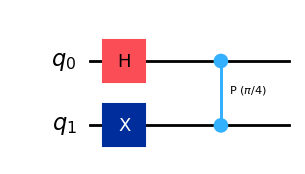

<IPython.core.display.Latex object>

In [36]:
theta = np.pi/4

q = QuantumRegister(2, 'q')
qc = QuantumCircuit(q)

qc.x(1)                  # put target in |1>
qc.h(0)                  # put control in |+> = (|0> + |1>)/sqrt(2)
qc.cp(theta, 0, 1)       # controlled phase on |11>

s = Statevector.from_instruction(qc)
display(qc.draw(output='mpl'))
display(s.draw('latex'))

## 8.2.2. How QPE works

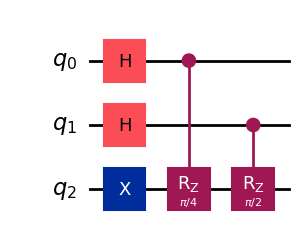

<IPython.core.display.Latex object>

In [37]:
theta = np.pi / 4  # phase to be estimated

# QPE with 2 control qubits + 1 target qubit
qc = QuantumCircuit(3)

# --- 1. Prepare target in eigenstate of U = Rz(theta) ---
qc.x(2)   # |1> is an eigenstate of Rz(theta)

# --- 2. Put control qubits in |+> ---
qc.h(0)
qc.h(1)

# --- 3. Apply controlled-U^(2^k) ---
qc.crz(theta, 0, 2)        # U^(2^0)
qc.crz(2 * theta, 1, 2)    # U^(2^1)

# --- 4. Extract statevector ---
display(qc.draw(output='mpl'))
s = Statevector.from_instruction(qc)
display(array_to_latex(s, prefix="\\text{s} = ", precision = 1))

## 8.2.3. How QPE extracts eigenvalues from molecular Hamiltonians

## 8.2.4. Building the qubit Hamiltonian, running VQE and QPE

In [38]:
def solve_vqe_qpe(
    estimator=Estimator(),
    moleculeinfo=None,
    basis="sto3g",
    mapper_name="Parity",
    num_electrons=None,
    num_spatial_orbitals=None,
    freeze_core=None,
    two_qubit_reduction=True,
    z2symmetry_reduction=None,
    name_solver='NumPy exact solver',
    n_ancillae=3, 
    maxiter=200, 
    learning_rate=0.01, 
    perturbation=0.7,
    show=True,
    show_VQE=False
):
    # Get a driver
    driver = PySCFDriver.from_molecule(
        moleculeinfo,
        basis=basis
    )

    # Splitting into classical and quantum
    if num_electrons != None and num_spatial_orbitals != None:
        split = ActiveSpaceTransformer(
            num_electrons=num_electrons,
            num_spatial_orbitals=num_spatial_orbitals
        )
    else:
        split = None

    # Define an electronic structure problem
    problem = driver.run()
    if split is not None:
        problem = split.transform(problem)
    elif freeze_core is not None:
        problem = freeze_core.transform(problem)
    
    # Get the electronic energy fermionic Hamiltonian
    fermionic_hamiltonian = problem.hamiltonian
    second_q_op = fermionic_hamiltonian.second_q_op()

    # Map the fermionic Hamiltonian to a qubit Hamiltonian
    qubit_op, mapper = fermion_to_qubit(
        problem,
        second_q_op,
        mapper_name,
        two_qubit_reduction=two_qubit_reduction,
        z2symmetry_reduction=z2symmetry_reduction,
        show=show
    )
    num_qubits = qubit_op.num_qubits
    print(f"Hamiltonian qubits: {num_qubits}")

    # Create the UCCSD ansatz
    UCCSD_ansatz = UCCSD(
        problem.num_spatial_orbitals,
        problem.num_particles,
        mapper,
        initial_state=HartreeFock(problem.num_spatial_orbitals,problem.num_particles,mapper)
    )

    # Run VQE
    E_elec, Total_energy, history = run_vqe_with_noise(
        name_solver,
        problem,
        mapper,
        num_qubits,
        maxiter=maxiter,
        learning_rate=learning_rate,
        perturbation=perturbation,
        optimizer=SPSA(maxiter=200),
        noise_model=None,
        show=show_VQE
    )
    print(f"VQE reference electronic ground state energy: {E_elec:4f}")
    print(f"VQE Total_energy: {Total_energy:4f}")

    # Run QPE 
    qpe_energy = run_qpe(
        problem,
        qubit_op,
        mapper,
        n_ancillae=n_ancillae,
        t=None,
        reference_energy=E_elec,
        show=show
    )
    print(f"qpe_energy: {qpe_energy:4f}")
    
    return qubit_op, UCCSD_ansatz, E_elec, Total_energy, qpe_energy

## 8.2.5. Running QPE on the hydrogen ($\text{H}_{2}$) molecule
### Defining the geometry of the $\text{H}_{2}$ molecule

In [39]:
# H2 molecule info
H2_atoms = ["H", "H"]
H2_coords = [(0.0, 0.0, 0.0), (0.0, 0.0, 0.735)]
H2_charge = 0
H2_multiplicity = 1
H2_atom_pair = (1, 0)

H2_moleculeinfo = MoleculeInfo(
    H2_atoms,
    H2_coords,
    charge=H2_charge,
    multiplicity=H2_multiplicity,
)

### Building the H2 qubit Hamiltonian, running VQE and QPE

In [40]:
H2_qubit_op, H2_UCCSD_ansatz, H2_Elec, H2_Total_energy, H2_qpe_energy = solve_vqe_qpe(
    moleculeinfo=H2_moleculeinfo,
    basis="sto3g",
    mapper_name="Parity",
    two_qubit_reduction = True,
    z2symmetry_reduction = None,
    show = True
)

Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 5
SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ', 'XX'],
              coeffs=[-1.05237325+0.j,  0.39793742+0.j, -0.39793742+0.j, -0.0112801 +0.j,
  0.1809312 +0.j])
Hamiltonian qubits: 2
VQE reference electronic ground state energy: -1.857275
VQE Total_energy: -1.137306

run_qpe diagnostics:
Hamiltonian qubits: 2
Identity shift: -1.0523732457728596
Spectral norm: 3.0928326452725448
Evolution time t: 1.0157654855304825

Chosen candidate: k=-1, alt_plus
Chosen energy:   -1.825581 Ha

Measured phase: 0.125
Ground state energy from QPE: -1.825581 Ha
qpe_energy: -1.825581


## 8.2.6. Running QPE on the lithium hydride (LiH) molecule
### Defining the geometry of the LiH molecule

In [41]:
LiH_atoms = ["Li", "H"]
LiH_coords = [(0.0, 0.0, 0.0), (0.0, 0.0, 1.5474)]
LiH_charge = 0
LiH_multiplicity = 1

LiH_moleculeinfo = MoleculeInfo(
    LiH_atoms,
    LiH_coords,
    charge=LiH_charge,
    multiplicity=LiH_multiplicity,
)

### Building the LiH qubit Hamiltonian, running VQE and QPE

In [42]:
LiH_qubit_op, LiH_UCCSD_ansatz, LiH_Elec, LiH_Total_energy, LiH_qpe_energy = solve_vqe_qpe(
    moleculeinfo=LiH_moleculeinfo,
    basis="sto3g",
    mapper_name="Parity",
    freeze_core=FreezeCoreTransformer(freeze_core=True, remove_orbitals=[4, 3]),
    two_qubit_reduction = True,
    n_ancillae=10,
    z2symmetry_reduction="auto",
    show = True
)

Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 100
SparsePauliOp(['IIII', 'IIIZ', 'IIZZ', 'IIZI', 'IIXZ', 'IIXI', 'IZII', 'IZIZ', 'ZXII', 'ZXIZ', 'IXII', 'IXIZ', 'XXII', 'XXIZ', 'YYII', 'YYIZ', 'ZZII', 'ZZIZ', 'XZII', 'XZIZ'],
              coeffs=[-0.20316606+0.j, -0.09275995+0.j, -0.21188984+0.j,  0.36525869+0.j,
  0.01938941+0.j,  0.01938941+0.j,  0.09275995+0.j, -0.12274244+0.j,
  0.00294114+0.j,  0.01192553+0.j,  0.00294114+0.j,  0.01192553+0.j,
 -0.0007428 +0.j, -0.0323953 +0.j,  0.0007428 +0.j,  0.0323953 +0.j,
 -0.21188984+0.j,  0.05628878+0.j, -0.01938941+0.j, -0.01277933+0.j])
Hamiltonian qubits: 4
VQE reference electronic ground state energy: -8.907396
VQE Total_energy: -7.881461

run_qpe diagnostics:
Hamiltonian qubits: 4
Identity shift: -0.20316606150092195
Spectral norm: 3.4381703180824514
Evolution time t: 0.9137396821405676

Chosen candidate: k=-2, alt_plus
Chosen energy:   -7.965910 Ha

Measured phase: 0.12890625
Ground state energ

## 8.2.7. Running QPE on the Beryllium Hydride ($BeH_2$) molecule
### Defining the geometry of the $BeH_2$ molecule

In [43]:
BeH2_atoms = ["Be", "H", "H"]
BeH2_coords = [
    (0.0, 0.0, 0.0),      # Be
    (0.0, 0.0, 1.316),    # H
    (0.0, 0.0, -1.316)    # H
]

BeH2_charge = 0
BeH2_multiplicity = 1

BeH2_moleculeinfo = MoleculeInfo(
    BeH2_atoms,
    BeH2_coords,
    charge=BeH2_charge,
    multiplicity=BeH2_multiplicity
)

### Building the $BeH_2$ qubit Hamiltonian, running VQE and QPE

In [44]:
BeH2_qubit_op, BeH2_UCCSD_ansatz, BeH2_Elec, BeH2_Total_energy, BeH2_qpe_energy = solve_vqe_qpe(
    moleculeinfo=BeH2_moleculeinfo,
    basis="sto3g",
    mapper_name="Parity",
    num_electrons=2,
    num_spatial_orbitals=2,
    two_qubit_reduction=True,
    z2symmetry_reduction=None,
    show=True,
    show_VQE=True
)

Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 5
SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ', 'XX'],
              coeffs=[-0.95014273+0.j,  0.18911399+0.j, -0.18911399+0.j, -0.04267782+0.j,
  0.01480597+0.j])
Hamiltonian qubits: 2
Running the VQE using the NumPy exact solver
Elapsed time: 0:00:00.034734

=== GROUND STATE ENERGY ===
 
* Electronic ground state energy (Hartree): -18.979049308486
  - computed part:      -1.285982560464
  - ActiveSpaceTransformer extracted energy part: -17.693066748022
~ Nuclear repulsion energy (Hartree): 3.417937912477
> Total ground state energy (Hartree): -15.561111396008
 
=== MEASURED OBSERVABLES ===
 
  0:  # Particles: 2.000 S: 0.000 S^2: 0.000 M: 0.000
 
=== DIPOLE MOMENTS ===
 
~ Nuclear dipole moment (a.u.): [0.0  0.0  0.0]
 
  0: 
  * Electronic dipole moment (a.u.): [0.0  0.0  0.0]
    - computed part:      [0.0  0.0  0.0]
    - ActiveSpaceTransformer extracted energy part: [0.0  0.0  0.0]
  > Dipole moment (a.

# 8.3. Quantum Imaginary-Time Evolution (QITE)

## 8.3.1. Setting-up the Qiskit VarQITE pipeline
### VarQITE set-up and evolution

In [45]:
def run_VarQITE(
    estimator=Estimator(),
    tau_final=2.0,
    num_steps=40,
    qubit_op=None,
    ansatz=None,
    show=False,
):
    if qubit_op is None:
        print("Missing parameter qubit_op")
        return None

    if ansatz is None:
        print("Missing parameter ansatz")
        return None
    
    # Check the consistency of the number of qubits
    if qubit_op.num_qubits != ansatz.num_qubits:
        print(f"Ansatz qubits:, {ansatz.num_qubits} does not match Hamiltonian qubits: {qubit_op.num_qubits}")
        return None

    # Display the depth of the ansatz quantum circuit
    circuit_depth = ansatz.decompose().depth()
    print(f"The depth of the ansatz quantum circuit is: {circuit_depth}")
    
    # Compute the imaginary time step
    delta_tau = tau_final / num_steps

    evolution_problem = TimeEvolutionProblem(
        hamiltonian=qubit_op,
        time=tau_final,
    )
    initial_params = np.zeros(len(ansatz.parameters), dtype=float)

    # Use ImaginaryMcLachlanPrinciple
    var_principle = ImaginaryMcLachlanPrinciple()

    var_qite = VarQITE(
        ansatz=ansatz,
        initial_parameters=initial_params,
        variational_principle=var_principle,
        estimator=estimator,
        num_timesteps=num_steps,
    )

    result = var_qite.evolve(evolution_problem)
    if show:
        print("Raw parameter_values from VarQITE:", result.parameter_values)

    # Extract full trajectory (shape: [num_steps+1, num_params])
    trajectory = np.array(result.parameter_values, dtype=float)
    
    # Final parameter vector
    final_params = trajectory[-1]
    
    # Build mapping {Parameter: value}
    param_list = list(ansatz.parameters)
    param_map = {p: float(v) for p, v in zip(param_list, final_params)}
    
    # Assign parameters
    final_circuit = ansatz.assign_parameters(param_map)
    
    # Compute energy (Qiskit ≥2.0 API)
    job = estimator.run([(final_circuit, qubit_op)])
    energy_final = job.result()[0].data.evs
    
    print("Final parameters:", final_params)
    print(f"Approximate electronic ground state energy (Hartree): {energy_final:4f}")

    return energy_final

## 8.3.2. Running VarQITE on the hydrogen ($\text{H}_{2}$) molecule
### Defining a simple parameter ansatz for $\text{H}_{2}$

In [46]:
theta = Parameter("θ")

ansatz = QuantumCircuit(2)
ansatz.x(0)          # HF reference for H2 in parity mapping
ansatz.ry(theta, 1)
ansatz.cx(1, 0)

print("Ansatz parameters:", ansatz.parameters)
print("Number of parameters:", len(ansatz.parameters))
assert len(ansatz.parameters) == 1, "Ansatz must have exactly one parameter."

simple_ansatz = ansatz

Ansatz parameters: ParameterView([Parameter(θ)])
Number of parameters: 1


### Running VarQITE on $\text{H}_{2}$

In [47]:
H2_VarQITE_energy = run_VarQITE(
    estimator=Estimator(),
    tau_final=2.0,
    num_steps=40,
    qubit_op=H2_qubit_op,
    ansatz=ansatz
)

The depth of the ansatz quantum circuit is: 2
Final parameters: [-0.2160839]
Approximate electronic ground state energy (Hartree): -1.857252


## 8.3.3. Running VarQITE on the lithium hydride (LiH) molecule

In [48]:
LiH_VarQITE_energy = run_VarQITE(
    estimator=Estimator(),
    tau_final=2.0,
    num_steps=10,
    qubit_op=LiH_qubit_op,
    ansatz=LiH_UCCSD_ansatz
)

The depth of the ansatz quantum circuit is: 9
Final parameters: [-0.00292999 -0.00184263 -0.00292957 -0.00184255 -0.01899151  0.04086334
  0.04089558 -0.10637538]
Approximate electronic ground state energy (Hartree): -1.088167


## 8.3.4. Running VarQITE on the $BeH_2$ molecule

In [49]:
BeH2_VarQITE_energy = run_VarQITE(
    estimator=Estimator(),
    tau_final=2.0,
    num_steps=10,
    qubit_op=BeH2_qubit_op,
    ansatz=BeH2_UCCSD_ansatz
)

The depth of the ansatz quantum circuit is: 4
Final parameters: [-3.65449500e-17  1.13115697e-16 -1.63477243e-02]
Approximate electronic ground state energy (Hartree): -1.285975


# 8.4. Quantum Lanczos and Subspace Expansion Methods
## 8.4.1. How QSE improves ground-state accuracy and gives access to excited states
### How QSE improves ground-state accuracy
### How QSE gives access to excited states
### How QSE Complements VQE

## 8.4.2. Implementing QSE
### Utility functions

In [50]:
def clean_op(op, tol=1e-10):
    op = 0.5 * (op + op.adjoint())
    op = op.simplify(atol=tol)

    if len(op.paulis) == 0:
        return None

    return op

In [51]:
def is_valid_operator(op, tol=1e-12):
    """
    Strict check to ensure operator is safe for Estimator.
    """
    if op is None:
        return False

    op = op.simplify(atol=tol)

    # No Pauli terms → invalid
    if len(op.paulis) == 0:
        return False

    # All coefficients ~ 0 → invalid
    if np.allclose(op.coeffs, 0.0, atol=tol):
        return False

    return True

### Building UCCSD excitation QSE operators

In [52]:
def build_uccsd_qse_operators(ansatz):
    n = ansatz.num_qubits
    ops = []

    # Identity always included
    ops.append(SparsePauliOp("I" * n))

    # --------------------------
    # Case 1: True UCCSD ansatz 
    # --------------------------
    if hasattr(ansatz, "operators"):
        for op in ansatz.operators:
            if op is None:
                continue

            op = op.simplify()
            if len(op.paulis) == 0:
                continue

            ops.append(op)

    # ---------------------------------
    # Case 2: Generic circuit fallback
    # ---------------------------------
    else:
        print("Ansatz is not UCCSD, using fallback basis")

        # Minimal physically meaningful basis
        for i in range(n):
            label = ["I"] * n
            label[i] = "Z"
            ops.append(SparsePauliOp("".join(label)))

        # Nearest-neighbor XX correlations
        for i in range(n - 1):
            label = ["I"] * n
            label[i] = "X"
            label[i + 1] = "X"
            ops.append(SparsePauliOp("".join(label)))

    return ops

### Setting-up the QSE pipeline

In [53]:
def run_QSE(estimator=Estimator(), qubit_op=None, ansatz=None):

    if qubit_op is None:
        print("Missing parameter qubit_op")
        return None

    if ansatz is None:
        print("Missing parameter ansatz")
        return None
        
    n_qubits = qubit_op.num_qubits

    # Check the consistency of the number of qubits
    if qubit_op.num_qubits != ansatz.num_qubits:
        print(f"Ansatz qubits:, {ansatz.num_qubits} does not match Hamiltonian qubits: {qubit_op.num_qubits}")
        return None

    # -------------
    # Step 1 — VQE
    # -------------
    vqe = VQE(
        ansatz=ansatz,
        optimizer=SPSA(maxiter=200),
        estimator=estimator,
    )
    result = vqe.compute_minimum_eigenvalue(qubit_op)
    print(f"Computed VQE electronic energy: {result.eigenvalue:4f}")
    psi0_params = np.array(result.optimal_point, dtype=float)

    # --------------------------------
    # Step 2 — UCCSD excitation basis
    # --------------------------------
    operators = build_uccsd_qse_operators(ansatz)
    n_ops = len(operators)

    print(f"QSE basis size: {n_ops}")

    H = np.zeros((n_ops, n_ops))
    S = np.zeros((n_ops, n_ops))
    
    jobs = []
    meta = []  # (matrix_type, i, j)

    # -----------------------------------------
    # Step 3 — Run estimator ONLY on valid ops
    # -----------------------------------------
    for i, Oi in enumerate(operators):
        for j, Oj in enumerate(operators):
    
            H_ij = clean_op(Oi.adjoint() @ qubit_op @ Oj)
            S_ij = clean_op(Oi.adjoint() @ Oj)
    
            # H matrix
            if is_valid_operator(H_ij):
                jobs.append((ansatz, H_ij, psi0_params))
                meta.append(("H", i, j))
            else:
                H[i, j] = 0.0
    
            # S matrix
            if is_valid_operator(S_ij):
                jobs.append((ansatz, S_ij, psi0_params))
                meta.append(("S", i, j))
            else:
                S[i, j] = 0.0

    # ------------------------------
    # Step 4 — Vectorized estimator 
    # ------------------------------
    result = estimator.run(jobs).result()
    values = np.array([res.data.evs for res in result])

    # ------------------------------
    # Step 5 — Reconstruct matrices
    # ------------------------------
    for k, (mat, i, j) in enumerate(meta):
        if mat == "H":
            H[i, j] = values[k]
        else:
            S[i, j] = values[k]

    # -----------------------
    # Step 6 — Stabilization
    # -----------------------
    H = 0.5 * (H + H.T)
    S = 0.5 * (S + S.T)

    # Canonical orthogonalization
    s_vals, s_vecs = np.linalg.eigh(S)

    threshold = 1e-8
    keep = s_vals > threshold

    S_inv_sqrt = s_vecs[:, keep] @ np.diag(1.0 / np.sqrt(s_vals[keep]))
    H_eff = S_inv_sqrt.T @ H @ S_inv_sqrt

    eigvals = np.linalg.eigvalsh(H_eff)

    return eigvals

### Running the QSE pipeline on the $H_2$ molecule

In [54]:
run_QSE(
    estimator=Estimator(),
    qubit_op=H2_qubit_op,
    ansatz=H2_UCCSD_ansatz
)

Computed VQE electronic energy: -1.857216
QSE basis size: 4


array([-1.85721618, -1.24459331, -0.88272221, -0.22496129])

### Running the QSE pipeline on the $LiH$ molecule

In [55]:
run_QSE(
    estimator=Estimator(),
    qubit_op=LiH_qubit_op,
    ansatz=LiH_UCCSD_ansatz
)

Computed VQE electronic energy: -1.086815
QSE basis size: 9


array([-1.08681464, -0.97039799, -0.95338878, -0.67547424, -0.46385834,
       -0.41761258, -0.32581109, -0.19955508,  0.02751726])

### Running the QSE pipeline on the $BeH_2$ molecule

In [56]:
run_QSE(
    estimator=Estimator(),
    qubit_op=BeH2_qubit_op,
    ansatz=BeH2_UCCSD_ansatz
)

Computed VQE electronic energy: -1.285958
QSE basis size: 4


array([-1.28595775, -1.00762939, -0.97801664, -0.52896713])

# 8.5. Sampling-based algorithms SQD and SKQD
## 8.5.1. Sample-based quantum diagonalization (SQD)

## 8.5.2. Sample-based Krylov quantum diagonalization (SKQD)

# 8.6. Resource estimation for fault-tolerant chemistry
# 8.7. Comparing advanced algorithms to VQE

# Conclusion

# References
[ASE_0] Atomic Simulation Environment (ASE), https://wiki.fysik.dtu.dk/ase/index.html

[H5py] Quick Start Guide, https://docs.h5py.org/en/stable/quick.html 

[Loredo_Qiskit] Robert Loredo, Chapter 3: Introducing and Installing Qiskit. Learn Quantum Computing with Python and IBM Quantum, Packt Publishing, 2025. ISBN 978-1803244808, https://www.amazon.fr/Learn-Quantum-Computing-Python-IBM/dp/1803244801/

[NumPy] NumPy: the absolute basics for beginners, https://numpy.org/doc/stable/user/absolute_beginners.html

[PyQMC] PyQMC, a python module that implements real-space quantum Monte Carlo techniques, https://github.com/WagnerGroup/pyqmc 

[PySCF] The Python-based Simulations of Chemistry Framework (PySCF), https://pyscf.org/

[Qiskit] Qiskit, https://qiskit.org/

[Qiskit_Aer_1] Qiskit Aer documentation, https://qiskit.github.io/qiskit-aer/ 

[Qiskit_Aer_2] NoiseModel, https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.NoiseModel.html 

[Qiskit_Nat_0] Qiskit_Nature, https://github.com/Qiskit/qiskit-nature/blob/main/README.md 

[Qiskit_Nature] Qiskit Nature overview, Qiskit Nature 0.7.2, https://qiskit-community.github.io/qiskit-nature/

[QuTiP] QuTiP, Plotting on the Bloch Sphere, https://qutip.readthedocs.io/en/qutip-5.0.x/guide/guide-bloch.html

[SciPy] Statistical functions (scipy.stats), https://projects.scipy.org/getting-started.html

## Qiskit packages versions

In [59]:
import qiskit
import qiskit_ibm_runtime
import qiskit_aer

print(f'Qiskit: {qiskit.__version__}')
print(f'Qiskit IBM Runtime: {qiskit_ibm_runtime.__version__}')
print(f"Qiskit Aer version: {qiskit_aer.__version__}")

Qiskit: 2.3.0
Qiskit IBM Runtime: 0.45.1
Qiskit Aer version: 0.17.2


## Qiskit Nature

In [60]:
import qiskit_nature
print(f"Qiskit Nature version: {qiskit_nature.__version__}")

Qiskit Nature version: 0.7.2


## Qiskit Algorithms

In [61]:
import qiskit_algorithms
print(f"Qiskit Algorithms version: {qiskit_algorithms.__version__}")

Qiskit Algorithms version: 0.4.0


## Python

In [62]:
%%bash
which python
python --version

/home/alain/miniconda3/bin/python
Python 3.13.12
